# Run 2: delayed priors, fixed FSQ, and a repeat of the VQ collapse

Settings: **Accelerator: GPU**, **Internet: On**, input: the output of the
*LibriSpeech preparation* notebook. Run with **Save Version → Save & Run All**.
Expected time: about 6 GPU hours.

| Run | Quantizer | Priors | Purpose |
|---|---|---|---|
| `vq_delayed` | VQ | on from step 4,000 | does VQ survive when the priors come later? |
| `fuzzy_delayed` | fuzzy | on from step 4,000 | same conditions, to compare quality at a matched rate |
| `fsq_delayed` | FSQ (levels 8, 6, 5, BatchNorm) | on from step 4,000 | is the fixed FSQ a fair baseline now? |
| `vq_start_seed1` | VQ | on from step 1 | does last night's collapse repeat with another seed? |

Runs 1 to 3 use a 500-step learning-rate warmup; run 4 copies last night's
settings exactly (no warmup), with only the seed changed.

In [1]:
%cd /kaggle/working
!rm -rf granular-speech-codec && git clone --depth 1 https://github.com/Mathindata/granular-speech-codec
%cd /kaggle/working/granular-speech-codec
!pip install -q -r requirements.txt
!git log -1 --format="code version: %h %s"

/kaggle/working
Cloning into 'granular-speech-codec'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 33 (delta 3), reused 19 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 1.29 MiB | 17.18 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/kaggle/working/granular-speech-codec
code version: e2572ea Run-2 notebook: create scratch folder, disk check, envelope experiment on speech


Unpack the archives into `/kaggle/temp` (created here; not saved as output). Expect 28539 and 2703 files.

In [2]:
import glob, os, subprocess
DATA = "/kaggle/temp"   # scratch space for this session only, not saved as output
os.makedirs(DATA, exist_ok=True)
arch = {os.path.basename(p): p for p in glob.glob("/kaggle/input/**/*.tar.gz", recursive=True)}
print(arch)
for name in ["dev-clean.tar.gz", "train-clean-100.tar.gz"]:
    subprocess.run(["tar", "xzf", arch[name], "-C", DATA], check=True)
!df -h /kaggle/temp
!find /kaggle/temp/LibriSpeech/train-clean-100 -name "*.flac" | wc -l
!find /kaggle/temp/LibriSpeech/dev-clean -name "*.flac" | wc -l

{'dev-clean.tar.gz': '/kaggle/input/notebooks/matinazad/libri-speech-prep-cpu/dev-clean.tar.gz', 'train-clean-100.tar.gz': '/kaggle/input/notebooks/matinazad/libri-speech-prep-cpu/train-clean-100.tar.gz'}
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  5.6T  2.5T  70% /
28539
2703


## Envelope experiment on real speech (CPU work, about 2 minutes)

200 clips of 4 s from dev-clean, spread over all its speakers. Each envelope
(peak, 5 %–95 % quantile, justifiable granularity) is computed on the clean clip
and on the same clip with 20 clicks added. Lower click distortion = more robust.

/kaggle/working/granular-speech-codec
{
  "peak": {
    "distortion": [
      0.18103215102823556,
      0.09595545004116199
    ],
    "coverage": [
      1.0,
      0.0
    ],
    "width": [
      0.999999999997103,
      1.221083434081829e-12
    ]
  },
  "quantile": {
    "distortion": [
      0.0008969602054639536,
      0.0005020920678360429
    ],
    "coverage": [
      0.9089896875,
      0.01492225902974416
    ],
    "width": [
      0.6807412436056844,
      0.06279691417557909
    ]
  },
  "granular": {
    "distortion": [
      0.013939181969121988,
      0.009009691219440013
    ],
    "coverage": [
      0.9780683593749999,
      0.008048228259616924
    ],
    "width": [
      0.7598581507434845,
      0.06754891135781918
    ]
  },
  "setup": {
    "clips": 200,
    "window": 320,
    "clicks": 20,
    "data": "/kaggle/temp/LibriSpeech/dev-clean"
  }
}
saved envelope_speech.png


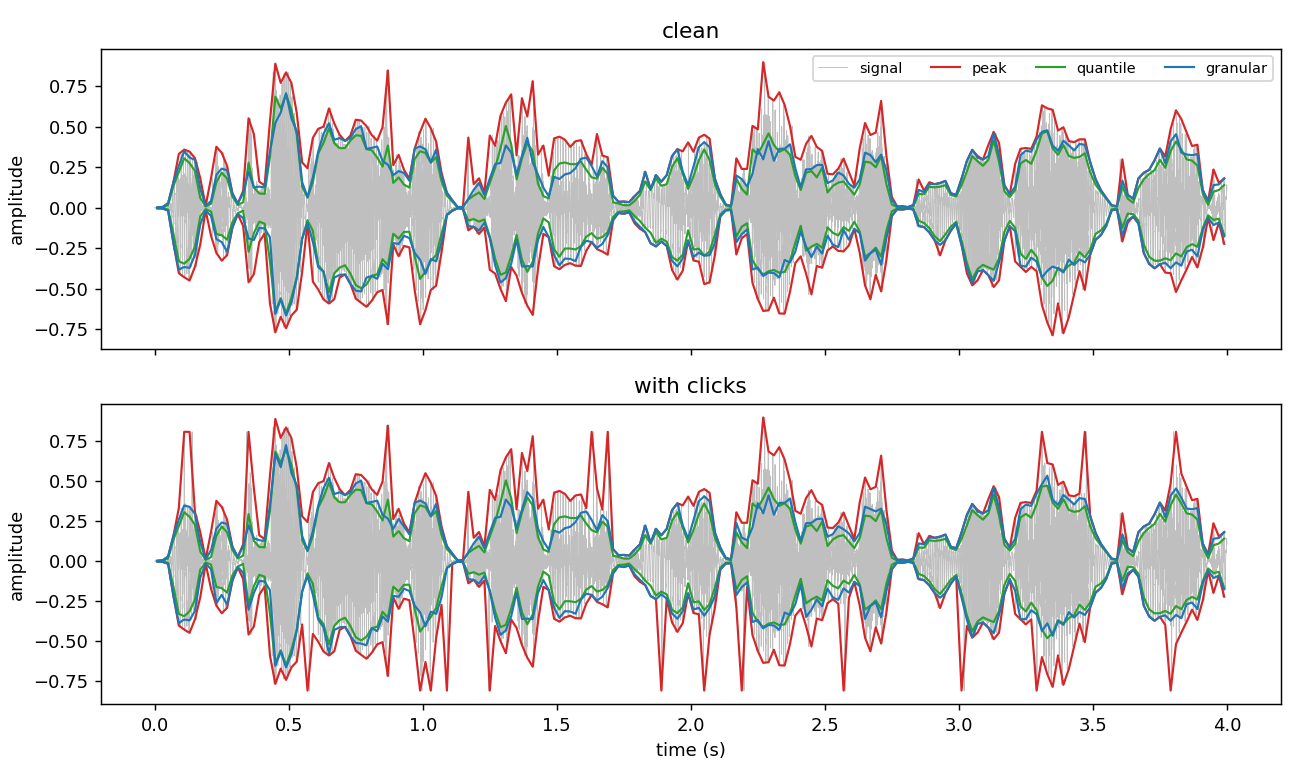

In [3]:
%cd /kaggle/working/granular-speech-codec
!python envelope_experiment.py --data_dir /kaggle/temp/LibriSpeech/dev-clean --clips 200 \
    --plot envelope_speech.png --out envelope_speech.json
from IPython.display import Image
Image("envelope_speech.png")

## Training

The order puts the most useful runs first. Each run evaluates and saves a checkpoint
every 2,000 steps.

In [4]:
%cd /kaggle/working/granular-speech-codec
COMMON = "--data_dir /kaggle/temp/LibriSpeech/train-clean-100 --eval_dir /kaggle/temp/LibriSpeech/dev-clean --eval_items 100 --workers 4 --log_every 200 --w_content 1 --w_speaker 1"
!python train.py {COMMON} --quantizer vq --steps 8000 --eval_every 2000 --warmup 500 \
    --content_start 4000 --speaker_start 4000 --out runs/vq_delayed

/kaggle/working/granular-speech-codec
params: 9.52 M, nominal rate 1600 bit/s
config.json: 100%|█████████████████████████| 1.60k/1.60k [00:00<00:00, 2.78MB/s]

model.safetensors: downloading bytes: ██████▉               |  120MB, 9.04MB/s  
model.safetensors: reconstructing file:  48%|██▊   |  180MB /  378MB            
model.safetensors: downloading bytes: █████████▏            |  158MB, 13.0MB/s  
model.safetensors: downloading bytes: ████████████▉         |  221MB, 18.5MB/s  
model.safetensors: downloading bytes: ██████████████▍       |  248MB, 20.7MB/s  
model.safetensors: downloading bytes: ██████████████████████|  254MB, 23.4MB/s  
model.safetensors: reconstructing file: 100%|██████|  378MB /  378MB, 35.2MB/s  
Loading weights: 100%|██████████████████████| 212/212 [00:00<00:00, 2349.01it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING

In [5]:
!python train.py {COMMON} --quantizer fuzzy --steps 8000 --eval_every 2000 --warmup 500 \
    --content_start 4000 --speaker_start 4000 --out runs/fuzzy_delayed

params: 9.52 M, nominal rate 1600 bit/s
Loading weights: 100%|██████████████████████| 212/212 [00:00<00:00, 2211.88it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|█████████████████████| 266/266 [00:00<00:00, 10596.00it/s]
{"step": 1, "loss": 5.231880187988281, "stft": 4.1341400146484375, "env": 1.0935943126678467, "aux": 0.004145766142755747, "m": 1.5, "alpha": 0.0, "reset": 0, "sec": 1.8}
{"step": 200, "loss": 3.6811890602111816, "stft": 2.736611843109131, "env": 0.9408267140388489, "aux": 0.0037504457868635654, "m": 1.4776125, "alpha": 0.04975, "reset": 0, "sec": 69.7}
{"step": 400, "loss": 2.9816982746124268, "stft": 2.4383206367492676, "env": 0.5326181054115295, "aux": 0.01075

In [6]:
!python train.py {COMMON} --quantizer fsq --fsq_levels 8,6,5 --steps 8000 --eval_every 2000 --warmup 500 \
    --content_start 4000 --speaker_start 4000 --out runs/fsq_delayed

params: 9.51 M, nominal rate 1581 bit/s
Loading weights: 100%|██████████████████████| 212/212 [00:00<00:00, 2456.32it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|█████████████████████| 266/266 [00:00<00:00, 15018.57it/s]
{"step": 1, "loss": 5.713078498840332, "stft": 4.267389297485352, "env": 1.445689082145691, "aux": 0.0, "m": 1.5, "alpha": 0.0, "reset": 0, "sec": 1.7}
{"step": 200, "loss": 2.696535587310791, "stft": 2.327866315841675, "env": 0.3686692416667938, "aux": 0.0, "m": 1.4776125, "alpha": 0.04975, "reset": 0, "sec": 69.2}
{"step": 400, "loss": 2.6585261821746826, "stft": 2.3120346069335938, "env": 0.34649166464805603, "aux": 0.0, "m": 1.4551125, "alpha": 0.09975, "rese

In [7]:
!python train.py {COMMON} --quantizer vq --steps 4000 --eval_every 2000 --seed 1 \
    --out runs/vq_start_seed1

params: 9.52 M, nominal rate 1600 bit/s
Loading weights: 100%|██████████████████████| 212/212 [00:00<00:00, 2626.17it/s]
[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|█████████████████████| 266/266 [00:00<00:00, 20817.35it/s]
{"step": 1, "loss": 6.609827041625977, "stft": 3.2933642864227295, "env": 0.9281981587409973, "aux": 0.004101631231606007, "content": 1.864130973815918, "speaker": 0.520031750202179, "m": 1.5, "alpha": 0.0, "reset": 0, "sec": 2.6}
{"step": 200, "loss": 6.755809307098389, "stft": 3.0815799236297607, "env": 1.172541856765747, "aux": 0.5100034475326538, "content": 1.4817395210266113, "speaker": 0.5099442601203918, "m": 1.455225, "alpha": 0.0995, "reset": 0, "sec": 2

## Results

Every evaluation of every run, then the last one of each on a plot.
Healthy codebook: dozens or more codes per group and a rate in the hundreds of bit/s.

In [8]:
import json
for run in ["vq_delayed", "fuzzy_delayed", "fsq_delayed", "vq_start_seed1"]:
    path = f"runs/{run}/eval.jsonl"
    if not os.path.exists(path):
        print(run, "no results"); continue
    for line in open(path):
        r = json.loads(line)
        print(f"{run:15s} step {r['step']:5d}  codes {r['codes_used']}  rate {r['entropy_bps']:5.0f}  "
              f"lsd {r['lsd_db']:5.1f}  spk {r.get('speaker_sim', float('nan')):.3f}  "
              f"wer {r.get('wer_vs_original', float('nan')):.2f}  kl {r.get('content_kl', float('nan')):.2f}")

vq_delayed      step  2000  codes [224, 229, 235, 236]  rate  1128  lsd  19.3  spk 0.565  wer 0.97  kl 2.41
vq_delayed      step  4000  codes [212, 189, 235, 186]  rate  1146  lsd  16.3  spk 0.655  wer 0.69  kl 1.94
vq_delayed      step  6000  codes [235, 221, 241, 223]  rate  1207  lsd  16.9  spk 0.850  wer 0.75  kl 1.94
vq_delayed      step  8000  codes [206, 202, 242, 220]  rate  1192  lsd  16.1  spk 0.859  wer 0.62  kl 1.79
fuzzy_delayed   step  2000  codes [190, 212, 227, 218]  rate  1095  lsd  22.4  spk 0.572  wer 1.01  kl 2.56
fuzzy_delayed   step  4000  codes [221, 240, 203, 222]  rate  1215  lsd  18.8  spk 0.613  wer 0.88  kl 2.27
fuzzy_delayed   step  6000  codes [235, 236, 209, 220]  rate  1245  lsd  17.8  spk 0.794  wer 0.87  kl 2.15
fuzzy_delayed   step  8000  codes [198, 218, 190, 200]  rate  1202  lsd  17.2  spk 0.805  wer 0.87  kl 2.12
fsq_delayed     step  2000  codes [224, 228, 236, 239]  rate  1236  lsd  19.6  spk 0.552  wer 0.97  kl 2.46
fsq_delayed     step  4000  

run                      quantizer  nominal  entropy           lsd_db      speaker_sim  wer_vs_original         envelope
fsq_delayed              fsq          1581     1403          15.7874           0.8534           0.5889           0.0832
fuzzy_delayed            fuzzy        1600     1202          17.1926           0.8055           0.8668           0.0912
vq_start_seed1           vq           1600       18          25.6930           0.4935           1.0000           1.1428
vq_delayed               vq           1600     1192          16.1269           0.8586           0.6237           0.0918
saved results.png


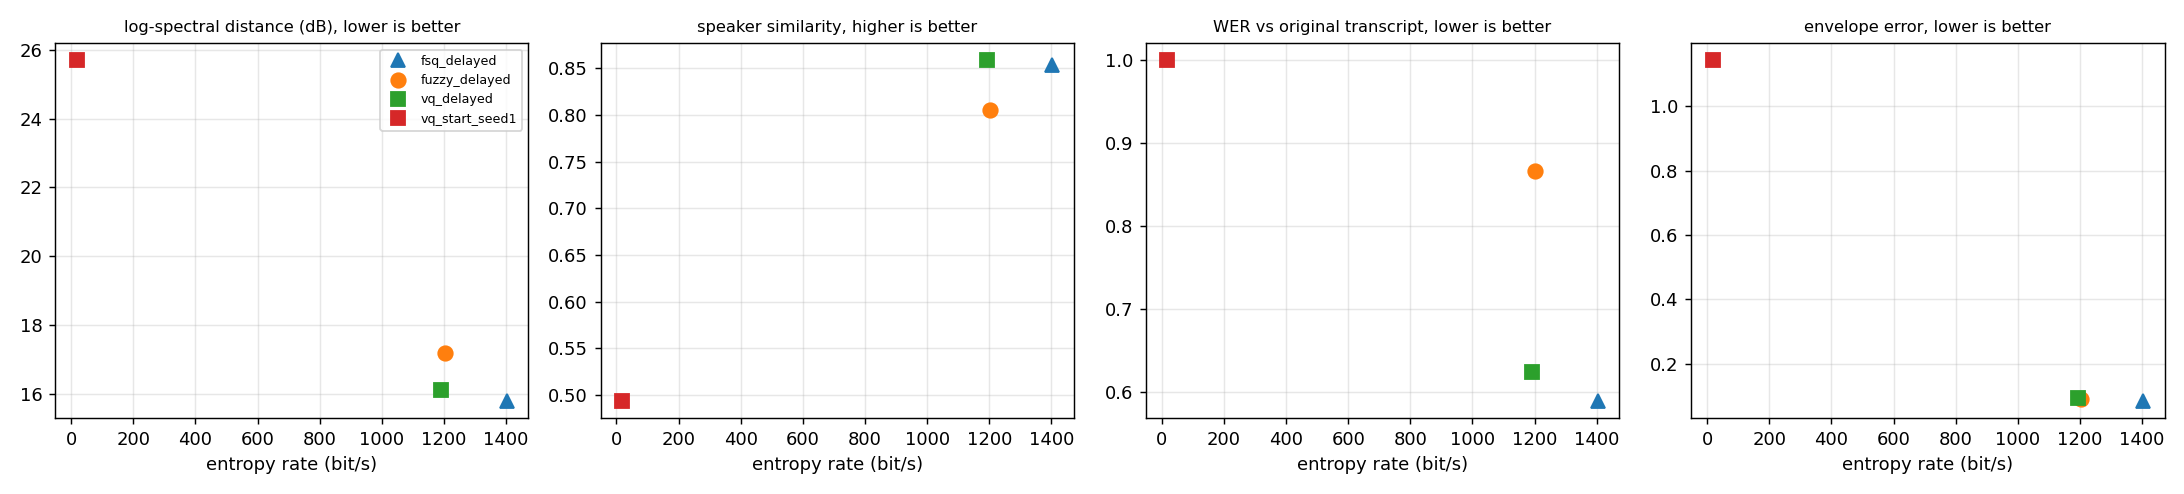

In [9]:
!python plot_results.py --runs runs --out results.png
from IPython.display import Image
Image("results.png")

## Part 2. Inspect a trained run

Set `RUN` to the run folder you want to look at. Everything below reads the
checkpoint and the logs from that folder. With only 200 training steps the
codec is barely trained, so expect noisy audio; the point is to see the
machinery. Run again after a long training run to see the real behavior.

In [10]:
import json, os
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Audio, HTML, display

os.chdir("/kaggle/working/granular-speech-codec")
from gsc.model import Codec
from gsc.data import AudioFolder
from gsc.quantizers import _split_groups
from gsc.rate import IndexHistogram

RUN = "runs/fuzzy_delayed"
EVAL_DIR = "/kaggle/temp/LibriSpeech/dev-clean"
N_CLIPS = 8           # 4-second clips used below
SR = 16000
device = "cuda" if torch.cuda.is_available() else "cpu"

ck = torch.load(f"{RUN}/checkpoint.pt", map_location=device, weights_only=False)
A = ck["args"]
fsq_levels = [int(v) for v in A["fsq_levels"].split(",")] if A.get("fsq_levels") else None
model = Codec(A["quantizer"], A["channels"], latent_dim=A["latent_dim"], groups=A["groups"],
              codebook_size=A["codebook_size"], code_dim=A["code_dim"], fsq_levels=fsq_levels).to(device)
model.load_state_dict(ck["model"])
model.eval()
QNAME, G, K = A["quantizer"], A["groups"], model.codebook_size
M_END = A["m_end"]

ds = AudioFolder(EVAL_DIR, "all", segment=4 * SR, max_files=N_CLIPS)
X = torch.stack([ds[i] for i in range(len(ds))]).to(device)       # (N, 1, 64000)
with torch.no_grad():
    Y, Q = model(X, m=M_END, alpha=1.0)                            # decoded speech
    P = _split_groups(model.quantizer.proj_in(Q["z"]), G)          # (N, G, T, d) pre-quantization points
FPS = SR / model.hop
print(f"run {RUN}: quantizer={QNAME}, step {ck['step']}, groups={G}, K={K}, "
      f"{FPS:.0f} frames/s, nominal {model.nominal_bits_per_frame() * FPS:.0f} bit/s")
print("latent points per group:", tuple(P.shape))

run runs/fuzzy_delayed: quantizer=fuzzy, step 8000, groups=4, K=256, 50 frames/s, nominal 1600 bit/s
latent points per group: (8, 4, 200, 8)


### 2.1 Learning curves

Each training term on its own axis, so a small term is not hidden by a big
one. The last panel shows the fuzzy schedule: `m` falls toward 1 and `alpha`
rises to 1 over the first half of training. Watch for a jump in the losses
when `alpha` reaches 1: that is the moment the decoder starts receiving hard
prototypes instead of soft mixtures.

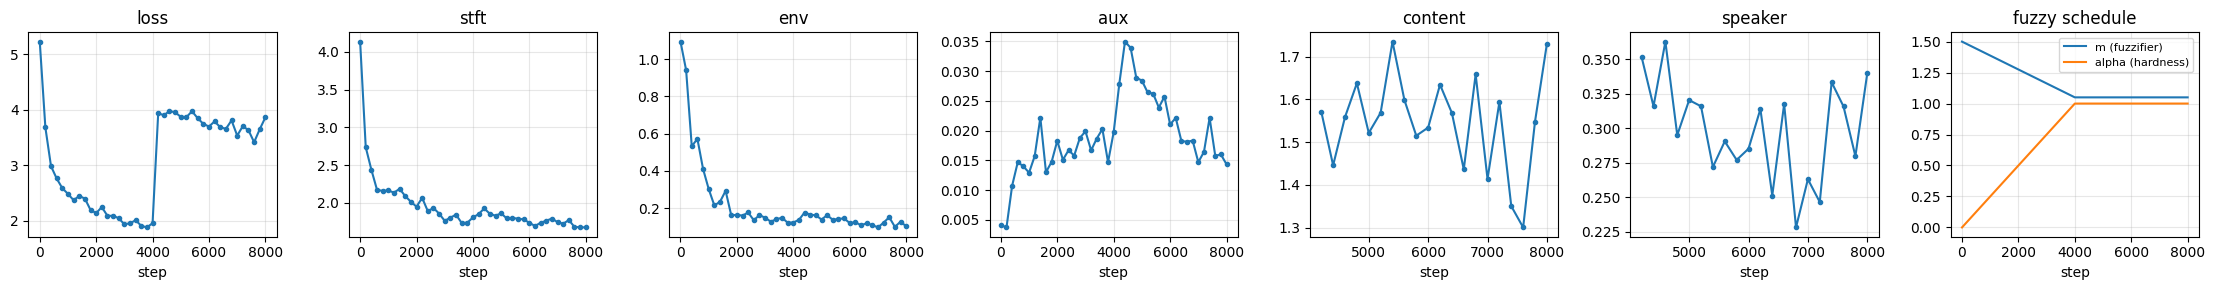

,quantizer,nominal_bps,entropy_bps,stft,envelope,lsd_db,speaker_sim,content_kl,wer_vs_original,step
0,fuzzy,1600,1094.5812,3.1186,0.3556,22.4031,0.5720,2.5620,1.0104,2000
1,fuzzy,1600,1214.8842,2.6400,0.1275,18.8277,0.6129,2.2700,0.8762,4000
2,fuzzy,1600,1244.5302,2.5148,0.1094,17.8131,0.7937,2.1508,0.8731,6000
3,fuzzy,1600,1201.8561,2.4393,0.0912,17.1926,0.8055,2.1205,0.8668,8000


In [11]:
log = pd.read_json(f"{RUN}/train_log.jsonl", lines=True)
terms = [c for c in ["loss", "stft", "env", "aux", "content", "speaker"] if c in log]
fig, axes = plt.subplots(1, len(terms) + 1, figsize=(3.2 * (len(terms) + 1), 3))
for ax, c in zip(axes, terms):
    ax.plot(log["step"], log[c], ".-")
    ax.set_title(c); ax.set_xlabel("step"); ax.grid(alpha=0.3)
ax = axes[-1]
ax.plot(log["step"], log["m"], label="m (fuzzifier)")
ax.plot(log["step"], log["alpha"], label="alpha (hardness)")
ax.set_title("fuzzy schedule"); ax.set_xlabel("step"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

ev = pd.read_json(f"{RUN}/eval.jsonl", lines=True)
display(ev.drop(columns=["codes_used"]).round(4))

### 2.2 Listen: original vs decoded

`normalize=False` keeps the true loudness, so a quiet output sounds quiet.
Below each pair: the two spectrograms (time on x, frequency on y, color =
log magnitude in dB). Missing high-frequency energy or smeared harmonics show
up here before you hear them.

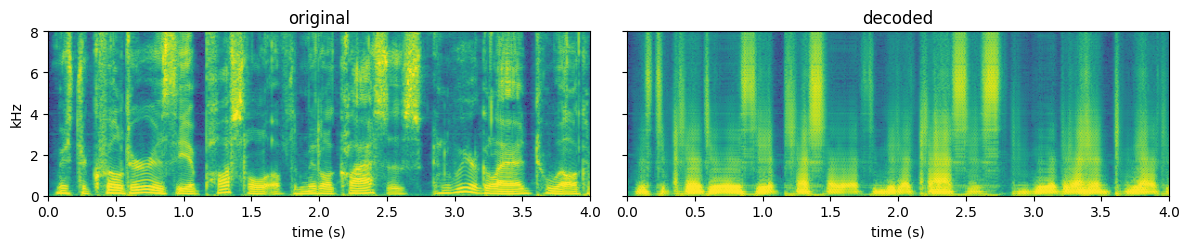

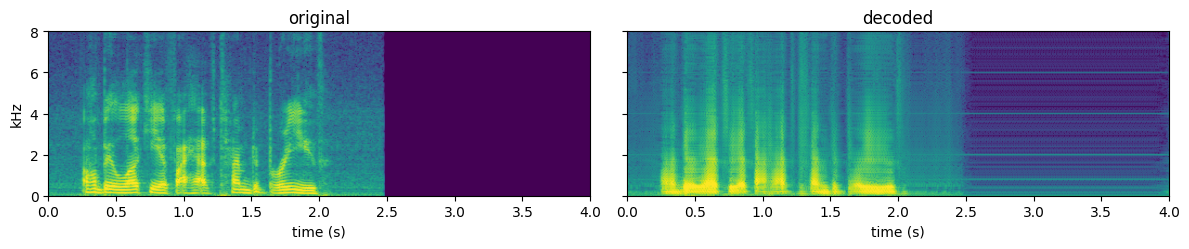

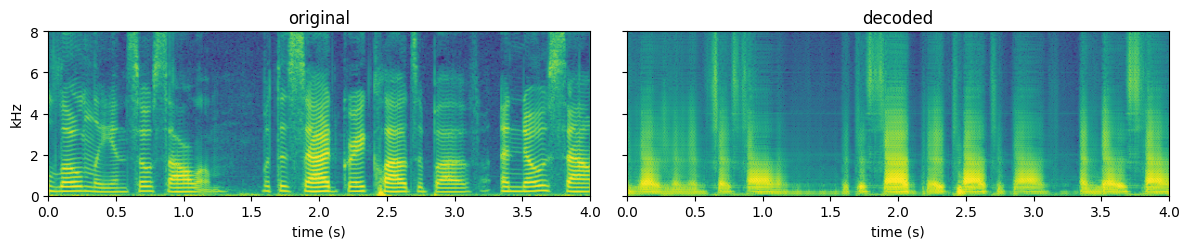

In [12]:
def spec_db(x):
    s = torch.stft(torch.as_tensor(x), 512, 128, window=torch.hann_window(512), return_complex=True)
    return 20 * torch.log10(s.abs() + 1e-6).numpy()

for i in range(min(3, len(X))):
    x, y = X[i, 0].cpu().numpy(), Y[i, 0].cpu().numpy()
    display(HTML(f"<b>clip {i}</b>: original, then decoded"))
    display(Audio(x, rate=SR, normalize=False))
    display(Audio(np.clip(y, -1, 1), rate=SR, normalize=False))
    fig, axes = plt.subplots(1, 2, figsize=(12, 2.6), sharey=True)
    for ax, s, t in [(axes[0], x, "original"), (axes[1], y, "decoded")]:
        ax.imshow(spec_db(s), origin="lower", aspect="auto", vmin=-80, vmax=20,
                  extent=[0, len(s) / SR, 0, SR / 2000])
        ax.set_title(t); ax.set_xlabel("time (s)")
    axes[0].set_ylabel("kHz"); plt.tight_layout(); plt.show()

### 2.3 Bit rate and code usage

Each group sends one index from 0 to K−1 per frame. If all K codes were used
equally, each index would cost log₂K bits. In practice some codes are used
far more than others, and an entropy coder spends fewer bits on frequent codes.
The entropy

  H = −Σ_k p_k log₂ p_k  (bits per index)

is that lower cost. Rate = Σ over groups of H × 50 frames/s.

The bars show how often each code was used, sorted. A short tail means only a
few codes are alive (codebook collapse); a long flat tail means the codebook
is well used.

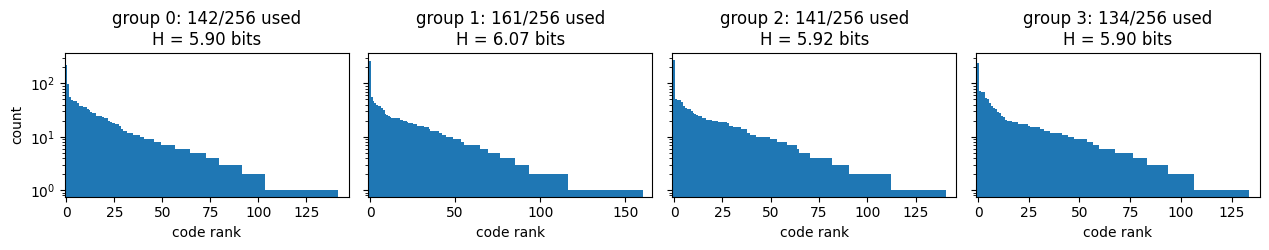

entropy rate 1190 bit/s  (nominal 1600 bit/s)


In [13]:
hist = IndexHistogram(G, K)
hist.update(Q["indices"])
p = hist.counts / hist.counts.sum(1, keepdim=True)
H = -(p * torch.log2(p.clamp_min(1e-300))).sum(1)
fig, axes = plt.subplots(1, G, figsize=(3.2 * G, 2.6), sharey=True)
for g in range(G):
    c = np.sort(hist.counts[g].numpy())[::-1]
    axes[g].bar(np.arange(K), c, width=1.0)
    axes[g].set_yscale("log"); axes[g].set_xlim(-1, max(20, int((c > 0).sum()) + 5))
    axes[g].set_title(f"group {g}: {int((c > 0).sum())}/{K} used\nH = {H[g]:.2f} bits")
    axes[g].set_xlabel("code rank")
axes[0].set_ylabel("count")
plt.tight_layout(); plt.show()
print(f"entropy rate {H.sum().item() * FPS:.0f} bit/s  (nominal {model.nominal_bits_per_frame() * FPS:.0f} bit/s)")

### 2.4 The latent space and the prototypes (granules)

Each frame of speech becomes a point in a small space (dimension `code_dim`)
for each group. The prototypes `v_1 … v_K` are the granule centers. Quantization
replaces each point by one prototype.

The space has more than 2 dimensions, so the plot uses PCA: it projects
everything onto the 2 directions along which the points vary most (the top
two right singular vectors of the centered data matrix). Colors = assigned
code. Black ×: prototypes, sized by how often they are used in these clips.

What to look for: prototypes should sit inside the cloud of points. Prototypes
far from every point are dead codes; one prototype covering a huge region
means coarse granulation there.

group 0: 142 of 256 prototypes used in these clips


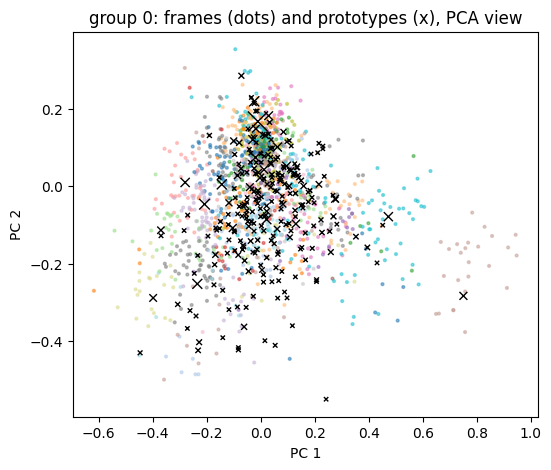

In [14]:
g = 0
pts = P[:, g].reshape(-1, P.shape[-1]).cpu().numpy()
idx = Q["indices"][:, g].reshape(-1).cpu().numpy()
mu = pts.mean(0)
_, _, Vt = np.linalg.svd(pts - mu, full_matrices=False)
proj = lambda a: (a - mu) @ Vt[:2].T
pp = proj(pts)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pp[:, 0], pp[:, 1], c=idx % 20, cmap="tab20", s=4, alpha=0.5)
if QNAME in ("vq", "fuzzy"):
    cb = model.quantizer.codebook[g].detach().cpu().numpy()
    used = np.bincount(idx, minlength=K)
    pc = proj(cb)
    ax.scatter(pc[:, 0], pc[:, 1], marker="x", c="k", s=10 + 200 * used / used.max(), lw=1)
    print(f"group {g}: {np.sum(used > 0)} of {K} prototypes used in these clips")
else:
    print("FSQ has no learned prototypes: its codes are the fixed grid of rounded levels")
ax.set_title(f"group {g}: frames (dots) and prototypes (x), PCA view")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()

### 2.5 Granulation over time (fuzzy quantizer only)

For one clip, group 0: the top panel is the spectrogram, the middle panel the
membership degrees `u_i(t)` of the most active prototypes, and the bottom
panel the largest membership per frame.

The membership formula (fuzzy c-means), with `d_i = ‖x − v_i‖`:

  u_i = 1 / Σ_j (d_i / d_j)^(2/(m−1))

So the memberships sum to 1, and the nearest prototype gets the largest
degree. A max membership near 1 means the frame sits clearly in one granule;
near 1/K means it sits between many. Look at whether granule changes line up
with changes in the spectrogram (phone boundaries, voiced vs silence).

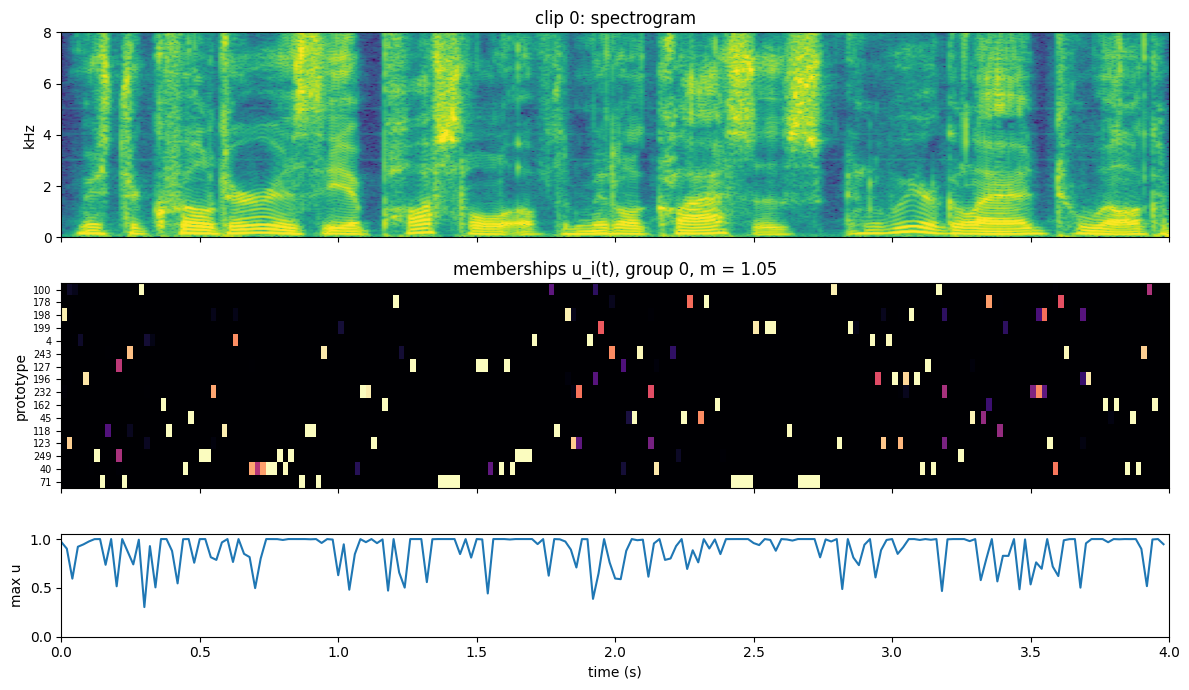

In [15]:
if QNAME != "fuzzy":
    print("This cell needs a fuzzy run.")
else:
    clip, g, top = 0, 0, 16
    u = Q["memberships"][clip, g].cpu().numpy()            # (T, K)
    order = np.argsort(-u.sum(0))[:top]
    T = u.shape[0]
    fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True,
                             gridspec_kw={"height_ratios": [2, 2, 1]})
    axes[0].imshow(spec_db(X[clip, 0].cpu().numpy()), origin="lower", aspect="auto",
                   vmin=-80, vmax=20, extent=[0, T / FPS, 0, SR / 2000])
    axes[0].set_ylabel("kHz"); axes[0].set_title(f"clip {clip}: spectrogram")
    im = axes[1].imshow(u[:, order].T, aspect="auto", origin="lower", cmap="magma",
                        extent=[0, T / FPS, -0.5, top - 0.5], vmin=0, vmax=1)
    axes[1].set_yticks(range(top)); axes[1].set_yticklabels(order, fontsize=7)
    axes[1].set_ylabel("prototype"); axes[1].set_title(f"memberships u_i(t), group {g}, m = {M_END}")
    axes[2].plot(np.arange(T) / FPS, u.max(1))
    axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("max u"); axes[2].set_xlabel("time (s)")
    plt.tight_layout(); plt.show()

### 2.6 What the fuzzifier m does

The same frame, coded with different values of `m`. For each `m`:

* **left:** the 10 largest memberships of one frame. Large `m` spreads the
  membership over many prototypes; as `m → 1` it concentrates on the nearest one
  (exponent `2/(m−1)` → ∞, so the smallest distance wins).
* **right:** the average squared error between a latent point `x` and its
  reconstruction, over all frames:
  * soft (degranulation): `x̂ = Σ u_i^m v_i / Σ u_i^m`
  * hard (nearest prototype): `x̂ = v_nearest`

At large `m` the soft mixture is pulled toward the codebook mean, so its error
is large. As `m → 1` it equals the hard prototype. This is why training lowers
`m`: the decoder must work with what is actually sent, the hard prototype.

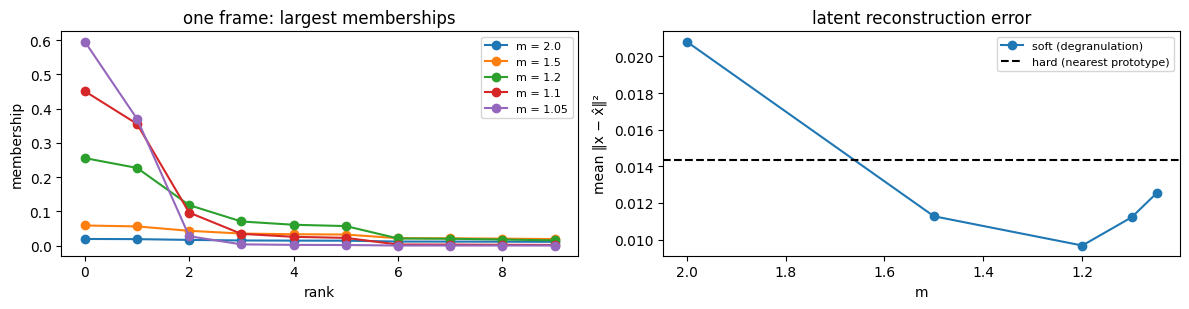

In [16]:
if QNAME != "fuzzy":
    print("This cell needs a fuzzy run.")
else:
    g, ms = 0, [2.0, 1.5, 1.2, 1.1, 1.05]
    fq = model.quantizer
    with torch.no_grad():
        D = fq._sq_dist(P)[:, g]                       # (N, T, K) squared distances
        x = P[:, g]
        cb = fq.codebook[g]
        frame = D[0, D.shape[1] // 2]                  # one frame, middle of clip 0
        soft_err, hard_err = [], (D.min(-1).values).mean().item()
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
        for mval in ms:
            u1 = fq.memberships(frame, mval).cpu().numpy()
            axes[0].plot(np.sort(u1)[::-1][:10], "o-", label=f"m = {mval}")
            u = fq.memberships(D, mval)
            w = u ** mval; w = w / w.sum(-1, keepdim=True)
            soft = w @ cb
            soft_err.append(((x - soft) ** 2).sum(-1).mean().item())
    axes[0].set_xlabel("rank"); axes[0].set_ylabel("membership"); axes[0].legend(fontsize=8)
    axes[0].set_title("one frame: largest memberships")
    axes[1].plot(ms, soft_err, "o-", label="soft (degranulation)")
    axes[1].axhline(hard_err, color="k", ls="--", label="hard (nearest prototype)")
    axes[1].set_xlabel("m"); axes[1].set_ylabel("mean ‖x − x̂‖²"); axes[1].invert_xaxis()
    axes[1].legend(fontsize=8); axes[1].set_title("latent reconstruction error")
    plt.tight_layout(); plt.show()

### 2.7 Perceptual priors: what the codec is asked to keep

**Content prior.** A pretrained speech recognizer (wav2vec 2.0) outputs, every
20 ms, a probability vector over 32 characters (letters, apostrophe, word
separator `|`, and a blank). This vector is a membership vector over
characters. The heatmaps show it for the original and the decoded speech; the
curve shows the per-frame KL divergence

  KL(p‖q) = Σ_c p_c log(p_c / q_c)

which is zero where the decoded speech gives the same character
probabilities. Training minimizes its average.

**Speaker prior.** A speaker model (WavLM x-vector) maps each clip to a unit
vector; the similarity is the cosine (1 = same voice).

**Transcripts.** Greedy decoding of both. The word error rate uses the
original's transcript as the reference, so it measures what the codec
destroyed, not mistakes of the recognizer.

This cell downloads the two models the first time (Internet must be on).

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

clip 0  speaker cos = 0.836   WER = 0.73
   original: MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELK
   decoded : CEADER AS THE OPPRESSOR OF THE MIDELASSES WORD LAND TO OUT
clip 1  speaker cos = 0.887   WER = 0.33
   original: I'LL BE LUCKY IF I HAVE TIME TO BREATHE
   decoded : I DO LETY IF I HAVE TIME TO BREATHE
clip 2  speaker cos = 0.759   WER = 0.69
   original: LONELY AND SO SOLEMN WITH THE SAD GRAY CLOUDS ABOVE AND NO SOU
   decoded : HIHIM TO SORROW TIT THE SAD PA TMOUT TO POUT AND NO SOU
mean speaker cosine over 8 clips: 0.837


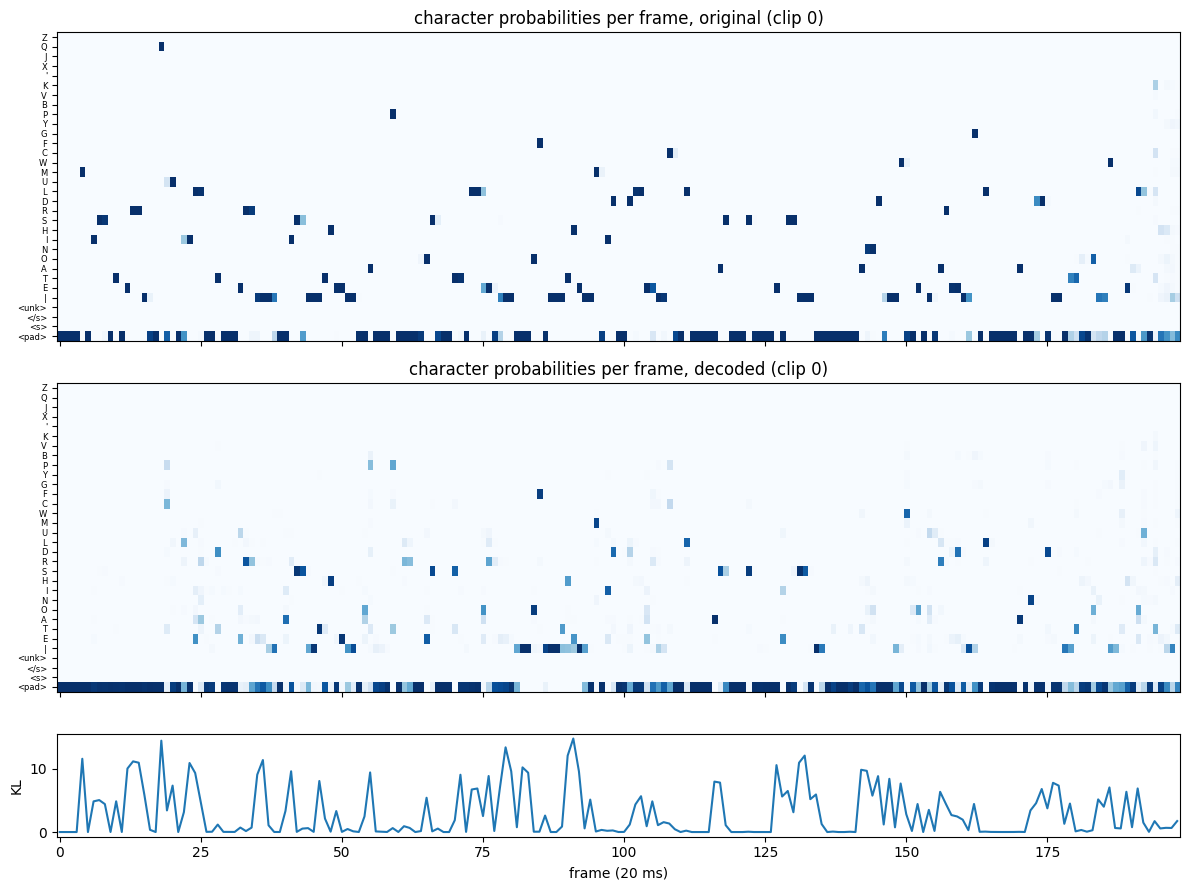

In [17]:
try:
    from gsc.priors import ContentPrior, SpeakerPrior, word_error_rate
    content, speaker = ContentPrior().to(device), SpeakerPrior().to(device)
except Exception as e:
    content = speaker = None
    print("priors not available:", type(e).__name__, e)

if content is not None:
    with torch.no_grad():
        sims = speaker.similarity(Y, X).cpu().numpy()
        refs, hyps = content.transcribe(X), content.transcribe(Y)
        lp = content.log_probs(X[:1])[0]; lq = content.log_probs(Y[:1])[0]
    kl_t = (lp.exp() * (lp - lq)).sum(-1).cpu().numpy()
    vocab = content.processor.tokenizer.convert_ids_to_tokens(list(range(lp.shape[-1])))

    for i in range(min(3, len(X))):
        print(f"clip {i}  speaker cos = {sims[i]:.3f}   WER = {word_error_rate(refs[i], hyps[i]):.2f}")
        print("   original:", refs[i]); print("   decoded :", hyps[i])
    print(f"mean speaker cosine over {len(X)} clips: {sims.mean():.3f}")

    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True,
                             gridspec_kw={"height_ratios": [3, 3, 1]})
    for ax, l, t in [(axes[0], lp, "original"), (axes[1], lq, "decoded")]:
        ax.imshow(l.exp().cpu().numpy().T, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1)
        ax.set_yticks(range(len(vocab))); ax.set_yticklabels(vocab, fontsize=6)
        ax.set_title(f"character probabilities per frame, {t} (clip 0)")
    axes[2].plot(kl_t); axes[2].set_ylabel("KL"); axes[2].set_xlabel("frame (20 ms)")
    plt.tight_layout(); plt.show()

### 2.8 Granules of the signal itself: the justifiable-granularity envelope

Here the granule is an interval `[a, b]` that summarizes the samples of one
20 ms window (320 samples). For the upper bound `b`, every sample above the
window median `med` is a candidate, and each candidate gets two scores:

* **coverage(b)** = fraction of the window's samples inside `[med, b]`.
  It grows as `b` grows.
* **specificity(b)** = 1 − (b − med)/R, with `R` the signal's range.
  It falls as `b` grows (a wider interval says less).

The chosen `b` maximizes coverage × specificity. The lower bound is chosen the
same way below the median.

**Left:** the three curves for the loudest window of clip 0, with the chosen
`b`. **Middle:** that window's samples, with the granular interval, the peak
interval (min, max) and the 5 %–95 % quantile interval. **Right:** the three
envelopes over the whole clip.

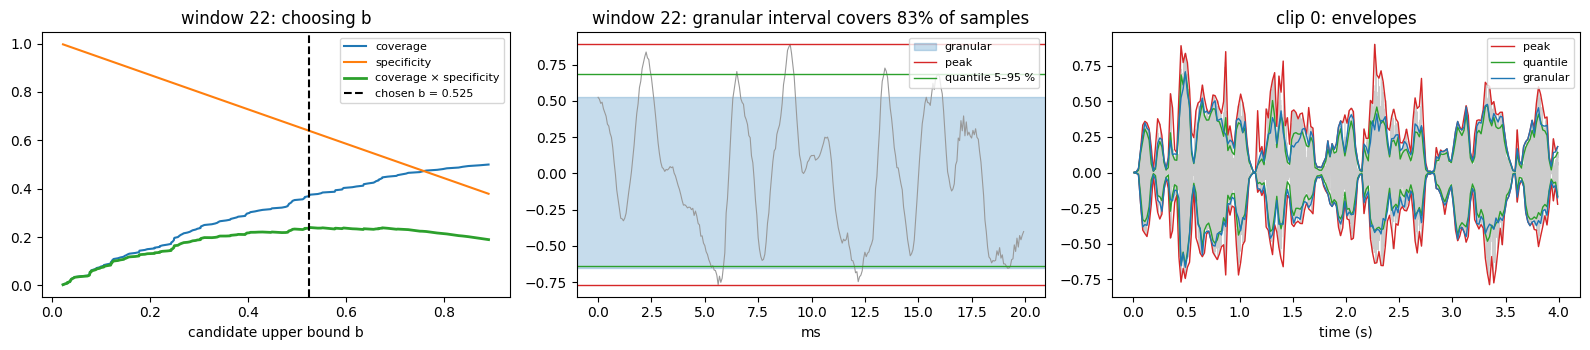

In [18]:
from gsc.envelope import granular_envelope, peak_envelope, quantile_envelope, robust_range

x = X[0, 0].cpu().numpy().astype(np.float64)
w = 320
R = robust_range(x)
W = x[: len(x) // w * w].reshape(-1, w)
k = np.argmax((W ** 2).mean(1))                    # loudest window
s, med = np.sort(W[k]), np.median(W[k])
cand = s[s >= med]
cov = np.arange(1, len(cand) + 1) / w
spec = np.clip(1 - (cand - med) / R, 0, None)
best = np.argmax(cov * spec)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].plot(cand, cov, label="coverage"); axes[0].plot(cand, spec, label="specificity")
axes[0].plot(cand, cov * spec, label="coverage × specificity", lw=2)
axes[0].axvline(cand[best], color="k", ls="--", label=f"chosen b = {cand[best]:.3f}")
axes[0].set_xlabel("candidate upper bound b"); axes[0].legend(fontsize=8)
axes[0].set_title(f"window {k}: choosing b")

lo_g, up_g = granular_envelope(x, w)
lo_q, up_q = quantile_envelope(x, w)
t = np.arange(w) / SR * 1000
axes[1].plot(t, W[k], color="0.6", lw=0.8)
axes[1].axhspan(lo_g[k], up_g[k], color="C0", alpha=0.25, label="granular")
for v, c, lab in [(W[k].max(), "C3", "peak"), (W[k].min(), "C3", None),
                  (up_q[k], "C2", "quantile 5–95 %"), (lo_q[k], "C2", None)]:
    axes[1].axhline(v, color=c, lw=1, label=lab)
inside = np.mean((W[k] >= lo_g[k]) & (W[k] <= up_g[k]))
axes[1].set_title(f"window {k}: granular interval covers {inside:.0%} of samples")
axes[1].set_xlabel("ms"); axes[1].legend(fontsize=8)

tt, tw = np.arange(len(x)) / SR, (np.arange(len(lo_g)) + 0.5) * w / SR
axes[2].plot(tt, x, color="0.8", lw=0.4)
for (lo, up), c, lab in [(peak_envelope(x, w), "C3", "peak"), ((lo_q, up_q), "C2", "quantile"),
                         ((lo_g, up_g), "C0", "granular")]:
    axes[2].plot(tw, up, color=c, lw=1, label=lab); axes[2].plot(tw, lo, color=c, lw=1)
axes[2].set_xlabel("time (s)"); axes[2].legend(fontsize=8); axes[2].set_title("clip 0: envelopes")
plt.tight_layout(); plt.show()